# Forecasting software revenue growth

Can linear regression improve on carrying forward the latest year-over-year revenue growth rate? We use SEC filings for eight software companies to forecast growth for the next fiscal quarter.

Run `python data.py` and `python features.py` first, then run this notebook from the project folder.

## Explore the data

Use the first available filing version for each company-quarter in this overview. Where standalone Q4 revenue is missing, the pipeline derives it from annual revenue minus nine-month revenue using figures available by the annual filing date. Fiscal dates follow each company, including Adobe's week-based calendar.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from backtest import MODELS, PREDICTORS, TARGET, backtest, summarize

panel = pd.read_parquet("data/processed/software_quarterly_versions.parquet")
first = panel.sort_values("filed").drop_duplicates(["ticker", "end"])
display(pd.DataFrame({
    "Fiscal quarters": first.groupby("ticker").size(),
    "Filing versions": panel.groupby("ticker").size(),
    "Derived quarters": first.method.ne("reported").groupby(first.ticker).sum(),
}))

,Fiscal quarters,Filing versions,Derived quarters
ticker,,,
ADBE,31,72,5
ADSK,31,73,5
CRM,31,67,6
INTU,31,61,8
MSFT,31,69,6
NOW,31,63,7
ORCL,31,64,8
WDAY,31,73,5


## Replay forecasts by filing date

At each forecast date from 2024 onward, use the latest revenue versions filed by the end of that day. Fit regression on earlier forecasts whose outcomes are already available. Score regression, persistence, and the four-quarter mean on the same rows. Mean absolute error (MAE) is measured in percentage points.

,ticker,forecast_as_of,growth_latest_pct,growth_previous_pct,growth_mean_4_pct,log_revenue,target_filed
0,ADBE,2021-01-15,14.438503,13.796754,15.267083,21.954075,2021-03-31
1,ADBE,2021-03-31,26.334520,14.438503,17.140986,22.085524,2021-06-30
2,ADBE,2021-06-30,22.602302,26.334520,19.293019,22.067435,2021-09-29
3,ADBE,2021-09-29,22.015504,22.602302,21.347707,22.093177,2022-01-21
4,ADBE,2022-01-21,20.035047,22.015504,22.746843,22.136689,2022-03-30


,Forecasts,Persistence,Four-quarter mean,Linear regression,Linear minus persistence
year,,,,,
2024,31,1.75,1.85,2.37,0.62
2025,32,1.94,2.61,2.00,0.06
2026,19,2.18,2.58,2.60,0.42
Overall,82,1.92,2.31,2.28,0.36


8 forecasts awaiting an outcome


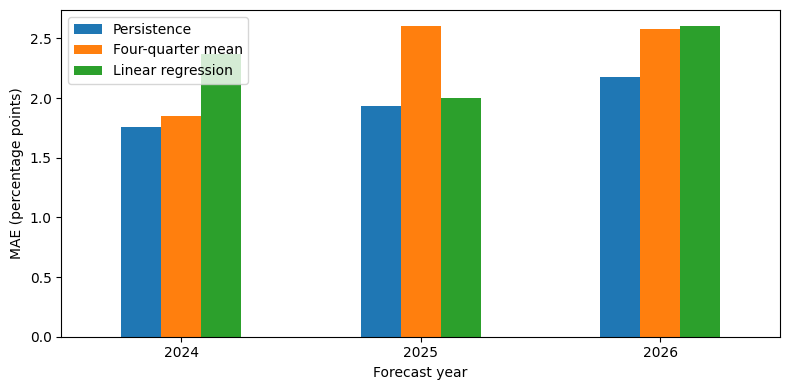

In [2]:
features = pd.read_parquet("data/features/software_features.parquet")
display(features[["ticker", "forecast_as_of", *PREDICTORS, "target_filed"]].head())

predictions = backtest(features)
scored = predictions.dropna(subset=[TARGET]).assign(year=lambda rows: rows.forecast_as_of.str[:4])
annual = summarize(scored, "year")
overall = summarize(scored.assign(year="Overall"), "year")
display(pd.concat([annual, overall]).round(2))
print(f"{predictions[TARGET].isna().sum()} forecasts awaiting an outcome")

ax = annual[list(MODELS.values())].plot.bar(rot=0, figsize=(8, 4))
ax.set(xlabel="Forecast year", ylabel="MAE (percentage points)")
plt.tight_layout()
plt.show()

## Examine errors by company

Negative differences favor regression. The five largest persistence misses show where carrying forward the latest growth rate broke down.

In [3]:
display(summarize(scored, "ticker").sort_values("Linear minus persistence").round(2))
display(scored.nlargest(5, "persistence_error_pp")[[
    "ticker", "forecast_as_of", TARGET, "persistence", "linear", "persistence_error_pp"
]].round(2))

,Forecasts,Persistence,Four-quarter mean,Linear regression,Linear minus persistence
ticker,,,,,
INTU,10,4.04,3.30,3.40,-0.64
ORCL,10,3.67,5.24,3.49,-0.19
NOW,11,1.77,1.65,1.87,0.11
ADSK,9,1.42,2.39,1.69,0.26
WDAY,10,1.07,1.47,1.58,0.50
CRM,10,1.35,1.78,2.03,0.68
MSFT,11,1.64,2.25,2.61,0.96
ADBE,11,0.55,0.68,1.58,1.04


,ticker,forecast_as_of,target_growth_pct,persistence,linear,persistence_error_pp
79,ORCL,2026-06-22,29.61,20.63,18.79,8.97
62,ORCL,2025-12-11,21.66,14.22,14.17,7.44
21,INTU,2024-09-04,10.24,17.40,17.44,7.16
66,INTU,2026-02-26,10.37,17.36,16.82,6.99
26,INTU,2024-11-21,17.04,10.24,13.01,6.80


## Conclusion

On the saved snapshot, persistence led in each year and scored 1.92 percentage points of MAE across 82 forecasts, compared with 2.28 for regression. The gap narrowed to 0.06 points in 2025. For these data, I would use persistence as the default and track its errors as new outcomes arrive.

The replay covers eight selected companies, with fewer observations in the newest year. Microsoft history was explored before this replay. A follow-up could save future predictions before the outcomes are filed and evaluate them with the same error metric.